## Test training


In [1]:
%load_ext autoreload
%autoreload 1

from cdxcore.verbose import Context
verbose = Context("all")
with verbose.write_t("Importing torch...", end='') as tme:   
    import torch
    verbose.write(f"done; this took {tme}.", head=False)

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.torch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler

from quantdata.dysanos.simple.sampler import SimpleSampler, SimpleConfig, SamplingConfig, ExpiryFilter, RawDayFilter, SampleDaysConfig, DateRange, PoolConfig
from cdxcore.verbose import Context
from datetime import date

def test():
    simple_config = SimpleConfig(
            tickers = ['SPX','NDX','RUT'],
            date_range = DateRange(start=date(2015, 1, 1), end=date(2025, 7, 1)),
            raw_day_filter = RawDayFilter(),
            expiry_filter = ExpiryFilter(),
            sample_days_config = SampleDaysConfig(),
            sampling_config = SamplingConfig(num_samples=20)
    )
    pool_config = PoolConfig(num_workers=4, threading=False) # no parallel processing for testing
    verbose = Context.all
    refresh_cache = False

    sampler = SimpleSampler(simple_config=simple_config, pool_config=pool_config, refresh_cache=refresh_cache, verbose=verbose)
    return sampler

sampler = test()
print("/done")

00: Importing torch...done; this took 0.75s.
00: Generating samples for 3 tickers NDX, RUT and SPX with from 2015-01-01 to 2025-07-01... done; this took 0.78s.
00: Found the following number of samples per ticker: NDX: 2617, RUT: 2617 and SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker NDX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
01:   Ticker RUT: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 1233 training samples and 309 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken

## Training a simple MLP

/model created.
01:   Trainer for 'AEC viz_train_vol_vol_deep_dec 0f5837ec6b870a6d' on data 0f5837ec6b870a6d
01:   ======================================================================================
02:     Restoring checkpoint from '/tmp/chkp/quantdata/dysanos/0f5837ec6b870a6d/viz_train_vol_vol_deep_dec 94d0bf20/last.pt'... done; this took 0.058s.
02:     Model is ready. Current epoch to train is 14.
01:   Launching 'AEC viz_train_vol_vol_deep_dec 0f5837ec6b870a6d' training for 1000 epochs over 1233 training and 309 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 2048 for valuation. The model has 74753 parameters. Resuming from epoch 14.
01:   Training 'viz_train_vol_vol_deep_dec' epoch 15/1000 error avg trn 0.007338; val 0.007347/0.01067 [1:15 5s 1.3s]. LR: 1.00e-03, GN 0.09212, excess: 0.008135/0.01182. ETA: 22:36:19.


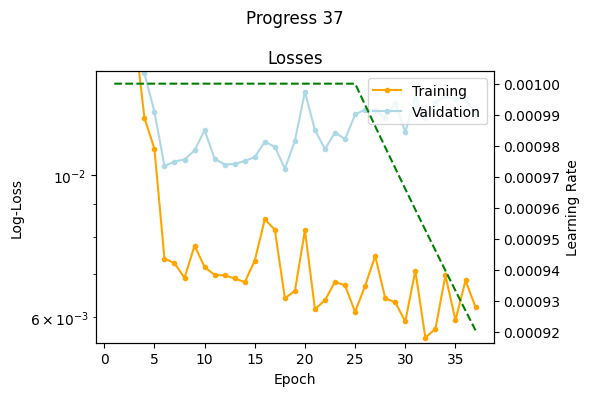

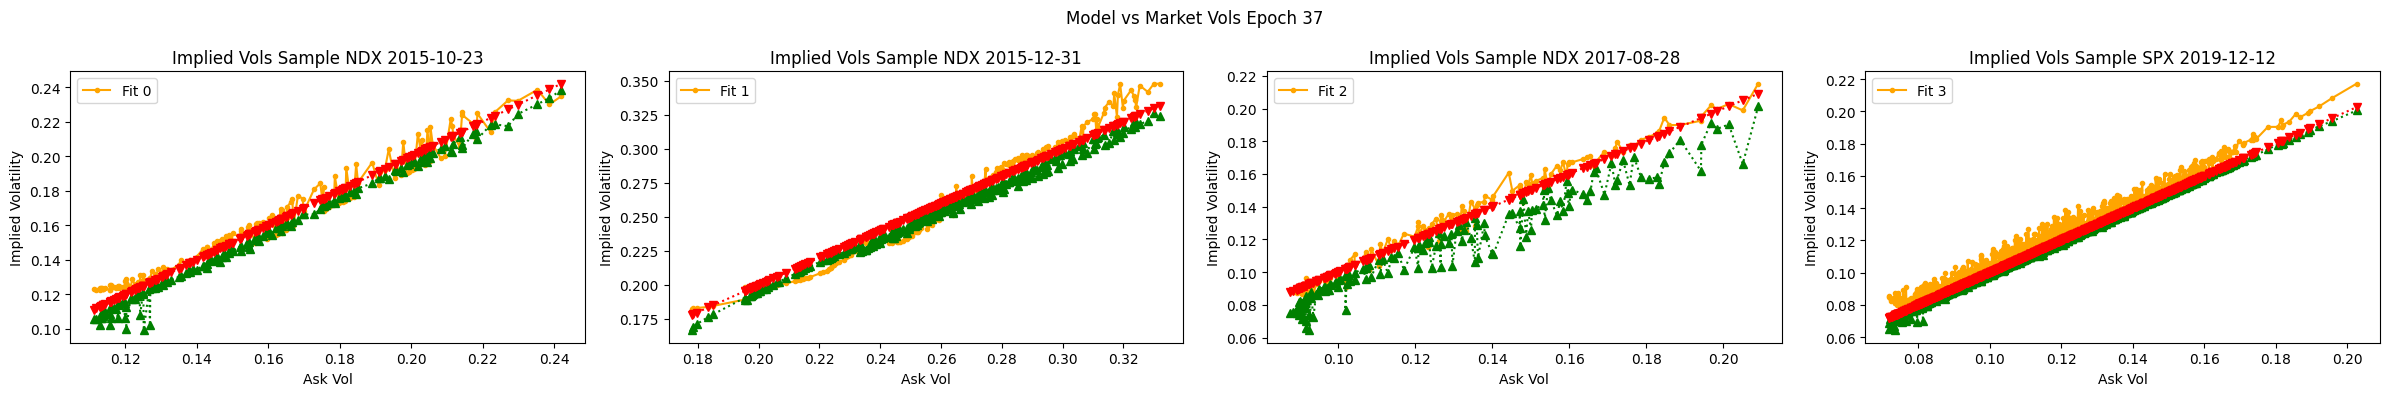

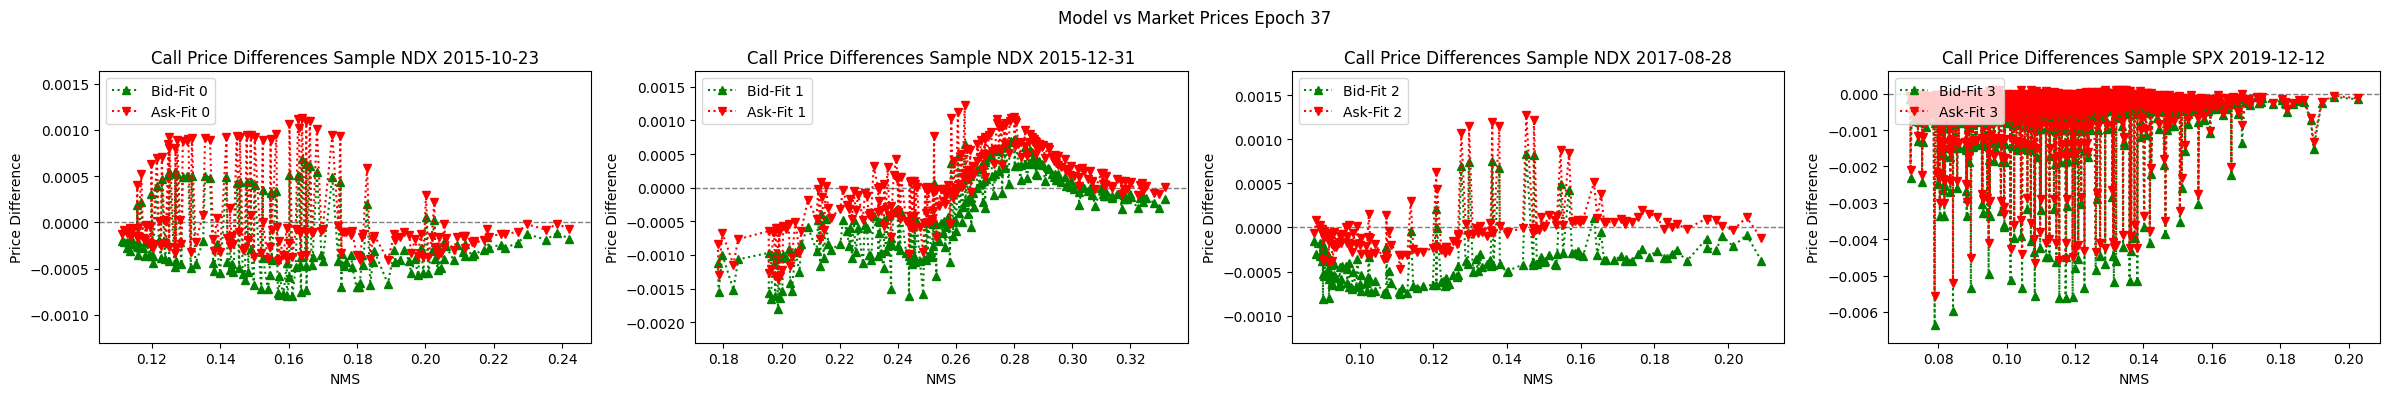

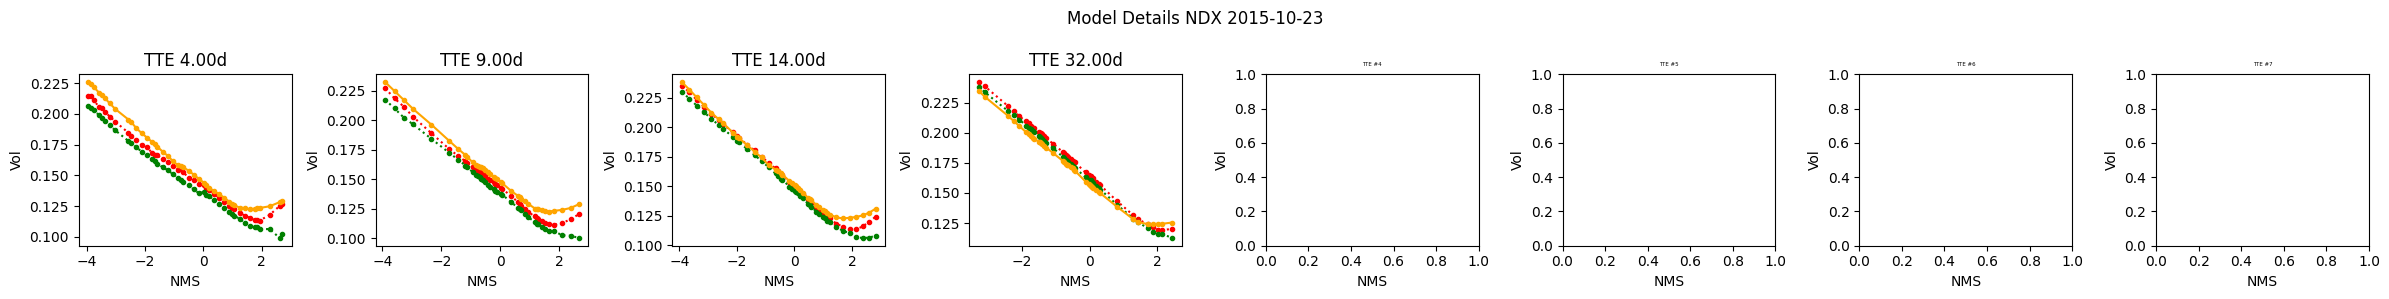

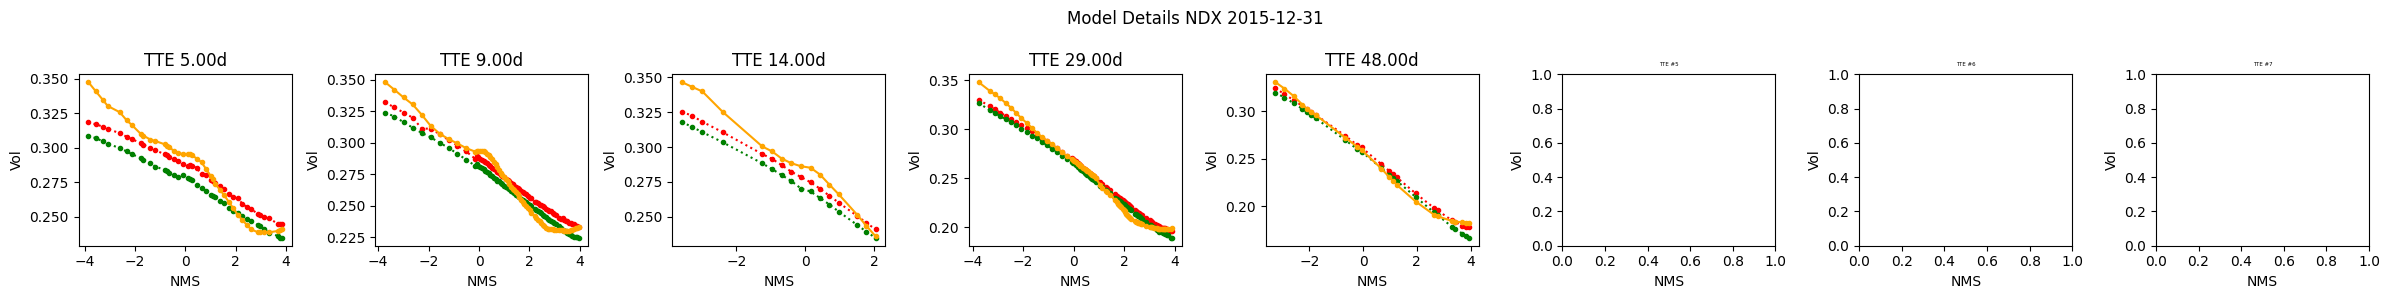

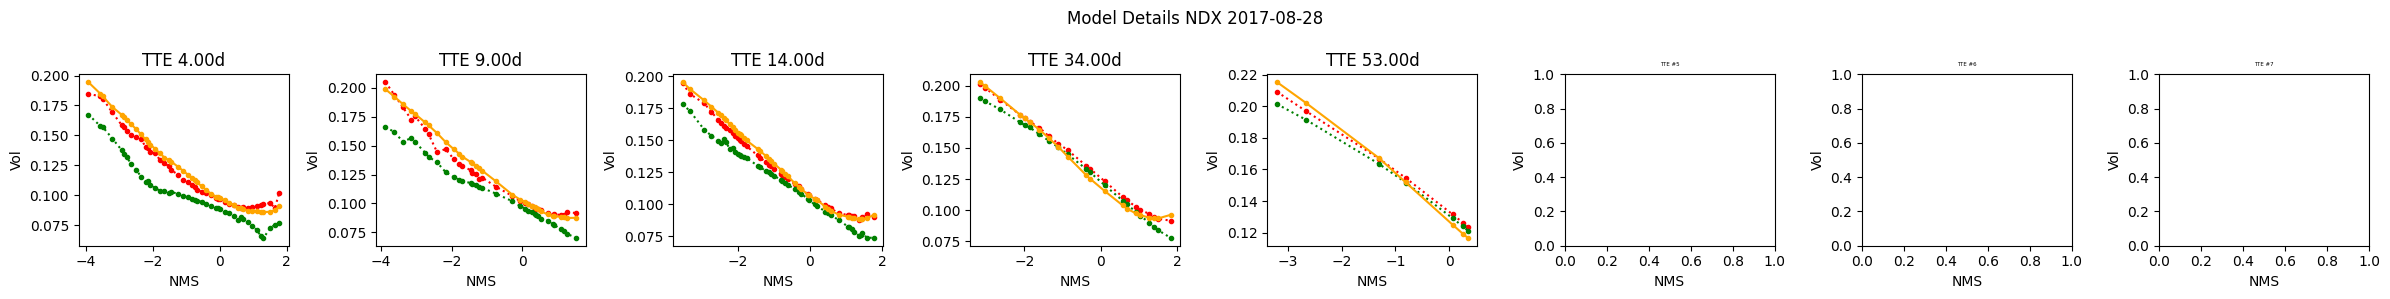

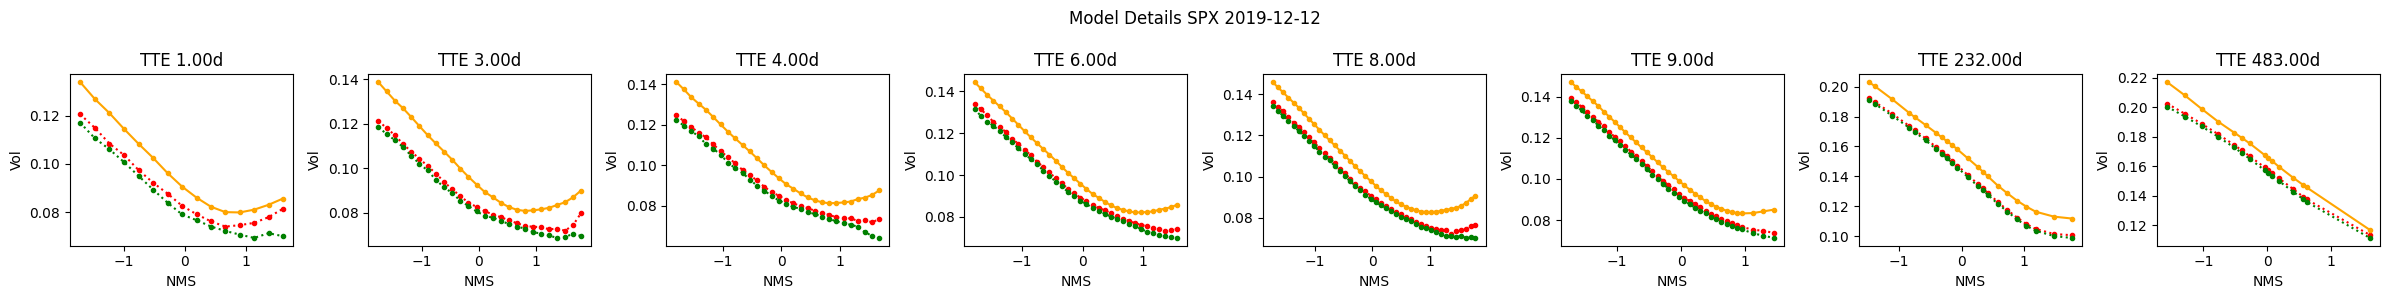

02:     Saving checkpoint to /tmp/chkp/quantdata/dysanos/0f5837ec6b870a6d/viz_train_vol_vol_deep_dec 94d0bf20/last.pt... done; this took 0.05s.
01:   Training 'viz_train_vol_vol_deep_dec' epoch 16/1000 error avg trn 0.007185; val 0.008528/0.01127 [1:15 5s 1.3s]. LR: 1.00e-03, GN 0.1137, excess: 0.009447/0.01249. ETA: 45:38:36.
02:     Saving checkpoint to /tmp/chkp/quantdata/dysanos/0f5837ec6b870a6d/viz_train_vol_vol_deep_dec 94d0bf20/last.pt... done; this took 0.049s.
01:   Training 'viz_train_vol_vol_deep_dec' epoch 17/1000 error avg trn 0.007058; val 0.00821/0.01108 [1:15 5s 1.3s]. LR: 1.00e-03, GN 0.06925, excess: 0.009095/0.01227. ETA: 68:29:30.
02:     Saving checkpoint to /tmp/chkp/quantdata/dysanos/0f5837ec6b870a6d/viz_train_vol_vol_deep_dec 94d0bf20/last.pt... done; this took 0.038s.
01:   Training 'viz_train_vol_vol_deep_dec' epoch 18/1000 error avg trn 0.006977; val 0.006414/0.01023 [1:15 5s 1.3s]. LR: 1.00e-03, GN 0.01067, excess: 0.007104/0.01133. ETA: 91:16:22.
02:     Ep

In [ ]:
# reloader

%aimport quantdata.utils.add_cdxcore
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.block_sampler
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer

from quantdata.dysanos.simple.model import AEC, BaseEnvironment, FeedForward
from quantdata.dysanos.simple.trainer import Trainer, TrainConfig
from cdxcore.subdir import SubDir
import ipynbname

env   = BaseEnvironment(device="cuda", debug=False)

aec_config = AEC.Config(
    num_state = 32,
    num_compress = 128   ,
    encode_what = "vol",
    fit_what="vol",
    mid_fit_weight = 0.1,
    fit_average = True,
    encoder_set_config = FeedForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'ReLU',
    ),
    encoder_fix_config = FeedForward.Config(
        num_depth = 3,
        num_width = 64,
        activation = 'ReLU',
    ),
    decoder_config = FeedForward.Config(
        num_depth = 3,
        num_width = 128,
        activation = 'ReLU',
    ),
    vizualizer_config = AEC.VisualizerConfig(details=True)  # set to None to turn off visualization
)

model = AEC(env=env, 
            shapes=sampler.shapes(), 
            stats=sampler.stats,
            num_steps=sampler.num_steps,
            max_options=sampler.max_options,
            config=aec_config )

print("/model created.")

train_config = TrainConfig(
    lr_init = 1E-3,
    lr_final = 1E-6,
    lr_init_steps = 25,
    trn_batch_size = 128,
    val_batch_size = 2048,
    batch_per_epoch = 100,
)

checkpoint = SubDir("!/chkp/quantdata/dysanos")

trainer = Trainer( label=ipynbname.name(), model=model, sampler=sampler, config=train_config, verbose=verbose(1), path=checkpoint )
_ = trainer(epochs=1000)
